# Showing the data via scanpy

In [1]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram

In [2]:
adata = sc.read_h5ad("./source_data/seurat_curated_6dpf.h5ad")
print(adata)

AnnData object with n_obs × n_vars = 30850 × 64955
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mtdna', 'percent.rrna', 'percent.goodgenes', 'seurat_clusters', 'S.Score', 'G2M.Score', 'Phase', 'clade_coarse_nj', 'vic_annotations', 'year_end_annotation_2022.coarse', 'cell_barcode', 'curated_48hpf.derived_annotations', 'biological_replicate', 'whitelisted_for_curation', 'nCount_SCT', 'nFeature_SCT', 'curated_high_res_annotations', 'coarse_clade_membership', 'celltype_family_20240924', 'group_full', 'group_slug', 'group_color', 'clade', 'subclade', 'subsubclade'
    uns: 'version'
    obsm: 'X_pca', 'X_umap'
    layers: 'RNA'


I have a 'RNA' layers instead of counts.

In [3]:
adata.layers['counts'] = adata.layers.pop('RNA')
adata.X = adata.layers['counts'].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

I do not need to redo the dimensionality reduction process, I saved it from Seurat...

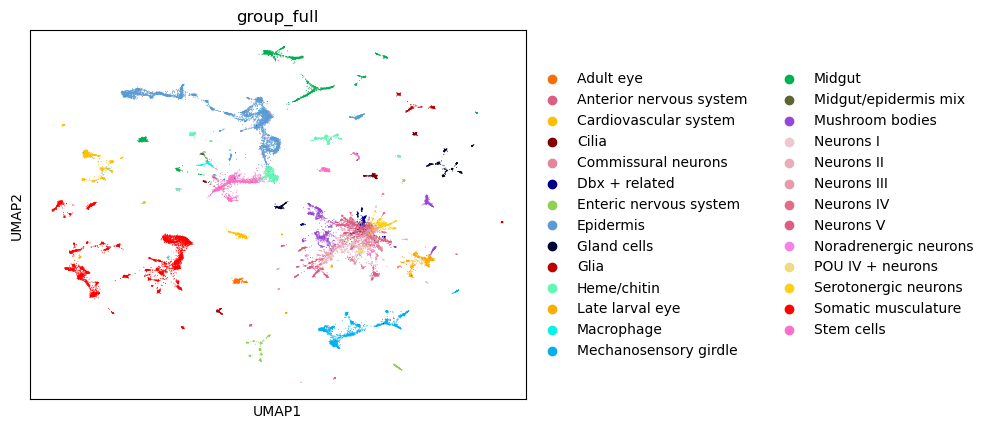

In [4]:
# I already have a defined color map
palette_dict = pd.Series(adata.obs['group_color'].values, index=adata.obs['group_full']).to_dict()
sc.pl.umap(
    adata,
    color="group_full",
    palette=palette_dict,
    size=2,
)

**In terms of metadata we care about:**
* `curated_high_res_annotations`:  Detlev's ~250 cell types (except 3 he likes but that are not in this curated object)
* `group_full`: Detlev's 20 or so big grouping, neurons are a bit hazy

I will reorder the types in a specific order.

In [5]:
cell_types_metadata = pd.read_csv("./prepped_data/subclade_ordering_color_scheme.tsv", sep="\t")

ordered_cell_types = cell_types_metadata['sub_membership'].drop_duplicates().str.strip().tolist()
print(f"Extracted cell type order: {ordered_cell_types}")

adata.obs['curated_high_res_annotations'] = pd.Categorical(
    adata.obs['curated_high_res_annotations'],
    categories=ordered_cell_types,
    ordered=True
)

ordered_tissue_types = cell_types_metadata['group_full'].drop_duplicates().str.strip().tolist()
print(f"Extracted tissue type order: {ordered_tissue_types}")

adata.obs['group_full'] = pd.Categorical(
    adata.obs['group_full'],
    categories=ordered_tissue_types,
    ordered=True
)


Extracted cell type order: ['clade5sub7', 'clade13sub9', 'clade5sub16', 'clade5sub9', 'nocladesub1', 'clade5sub5', 'clade5sub12', 'clade7sub10', 'clade7sub6', 'clade2sub10', 'clade7sub8', 'clade6sub25', 'clade6sub27', 'clade6sub28', 'clade6sub26', 'nocladesub33', 'clade6sub22', 'nocladesub2', 'nocladesub10', 'nocladesub12', 'nocladesub26', 'nocladesub20', 'clade6sub19', 'clade6sub14', 'nocladesub4', 'nocladesub8', 'clade6sub24', 'clade6sub7', 'clade6sub23', 'clade6sub21', 'clade6sub16', 'clade6sub9', 'clade6sub13', 'clade6sub11', 'clade6sub15', 'clade6sub17', 'nocladesub24', 'nocladesub3', 'nocladesub11', 'nocladesub15', 'nocladesub25', 'nocladesub35', 'clade7sub7', 'clade1sub12', 'nocladesub22', 'clade1sub18', 'clade1sub17', 'clade1sub13', 'clade1sub4', 'clade1sub19', 'clade1sub11', 'clade1sub3', 'clade1sub16', 'clade1sub14', 'clade1sub7', 'clade1sub2', 'nocladesub9', 'nocladesub29', 'clade3.2sub22', 'clade3.2sub18', 'clade3.2sub14', 'clade3.2sub20', 'clade3.2sub13', 'clade3.2sub16', 

I will rename my features to `XLOC | symbol`.

In [6]:
genes_metadata = pd.read_csv("./prepped_data/genes_metadata.tsv", sep="\t")
genes_metadata

,Unnamed: 0,ProsPR gene,Published name,pdumV2-1,Platybrowser name,XLOC,XLOC_full
0,0,Glt1,Glt1,XLOC_001410,glt1,XLOC-001410,XLOC-001410 | glt1
1,2,ANPRA,NaN,XLOC_025950,anpra,XLOC-025950,XLOC-025950 | anpra
2,4,AP2,ap2,XLOC_002429,ap2,XLOC-002429,XLOC-002429 | ap2
3,5,ASCb,ASCb,XLOC_008377,ascb,XLOC-008377,XLOC-008377 | ascb
4,6,AllCR1,NaN,XLOC_022100,allcr1,XLOC-022100,XLOC-022100 | allcr1
...,...,...,...,...,...,...,...
171,197,brn124,NaN,XLOC_005393,brn124,XLOC-005393,XLOC-005393 | brn124
172,198,nompc3,NaN,XLOC_002090,nompc3,XLOC-002090,XLOC-002090 | nompc3
173,199,pkd1,PKD1-1,XLOC_027897,pkd1,XLOC-027897,XLOC-027897 | pkd1
174,200,pkd2,PKD2-1,XLOC_026080,pkd2,XLOC-026080,XLOC-026080 | pkd2


In [7]:
genes_lookup = dict(zip(genes_metadata['XLOC'], genes_metadata['XLOC_full']))
genes_lookup

{'XLOC-001410': 'XLOC-001410 | glt1',
 'XLOC-025950': 'XLOC-025950 | anpra',
 'XLOC-002429': 'XLOC-002429 | ap2',
 'XLOC-008377': 'XLOC-008377 | ascb',
 'XLOC-022100': 'XLOC-022100 | allcr1',
 'XLOC-025660': 'XLOC-025660 | allcr2',
 'XLOC-044659': 'XLOC-044659 | arx',
 'XLOC-004258': 'XLOC-004258 | ash',
 'XLOC-056544': 'XLOC-056544 | barh1',
 'XLOC-003898': 'XLOC-003898 | beta3',
 'XLOC-009861': 'XLOC-009861 | bmpr1',
 'XLOC-000129': 'XLOC-000129 | brn3a',
 'XLOC-028320': 'XLOC-028320 | coe',
 'XLOC-026597': 'XLOC-026597 | chat',
 'XLOC-021496': 'XLOC-021496 | chx10',
 'XLOC-003551': 'XLOC-003551 | dach',
 'XLOC-018534': 'XLOC-018534 | dbhlike',
 'XLOC-020366': 'XLOC-020366 | dopard2',
 'XLOC-053880': 'XLOC-053880 | pgam',
 'XLOC-015543': 'XLOC-015543 | upp',
 'XLOC-008954': 'XLOC-008954 | unc22',
 'XLOC-014514': 'XLOC-014514 | ndus1',
 'XLOC-021313': 'XLOC-021313 | odo2',
 'XLOC-018549': 'XLOC-018549 | fxl21',
 'XLOC-012281': 'XLOC-012281 | ryr2',
 'XLOC-001169': 'XLOC-001169 | ppib'

In [8]:
assert(not set(genes_lookup.keys()).difference(set(adata.var_names.to_list())))
subset_adata = adata[:, adata.var_names.isin(genes_lookup.keys())].copy()
subset_adata

AnnData object with n_obs × n_vars = 30850 × 174
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mtdna', 'percent.rrna', 'percent.goodgenes', 'seurat_clusters', 'S.Score', 'G2M.Score', 'Phase', 'clade_coarse_nj', 'vic_annotations', 'year_end_annotation_2022.coarse', 'cell_barcode', 'curated_48hpf.derived_annotations', 'biological_replicate', 'whitelisted_for_curation', 'nCount_SCT', 'nFeature_SCT', 'curated_high_res_annotations', 'coarse_clade_membership', 'celltype_family_20240924', 'group_full', 'group_slug', 'group_color', 'clade', 'subclade', 'subsubclade'
    uns: 'version', 'log1p', 'group_full_colors'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts'

In [9]:
subset_adata.var['XLOC'] = subset_adata.var_names
subset_adata.var_names = subset_adata.var_names.to_series().map(genes_lookup).tolist()

In [10]:
print(subset_adata.var_names)

Index(['XLOC-000033 | hand', 'XLOC-000129 | brn3a', 'XLOC-000131 | trk',
       'XLOC-000375 | hcn1', 'XLOC-000555 | gcb', 'XLOC-000718 | kv33b',
       'XLOC-000791 | nov29', 'XLOC-000875 | syt', 'XLOC-000971 | twist',
       'XLOC-001169 | ppib',
       ...
       'XLOC-064375 | bca1', 'XLOC-064638 | gpcr203', 'XLOC-066432 | vegfr',
       'XLOC-067105 | grm7', 'XLOC-067814 | rims', 'XLOC-067936 | psmf1',
       'XLOC-068990 | kv33e', 'XLOC-069315 | trpv5', 'XLOC-026293 | ato2',
       'XLOC-043332 | gpcr2'],
      dtype='object', length=174)


I will order the features. TODO

I will do a giant dotplot of what we have for Platybrowser. Let's define some arguments we want to play with from https://scanpy.readthedocs.io/en/stable/api/generated/classes/scanpy.pl.DotPlot.html
I will reuse them later.

In [11]:
extra_args = {
    "expression_cutoff": 0,
    "standard_scale": "group", # None #  "var"
    "mean_only_expressed": False
}

You get the big group names and the the clades. We could play with the order, but not for now. Some markers are super high everywhere, others like `unc-22` are good markers for a group like `Somatic musculature`. Some are super sparse.

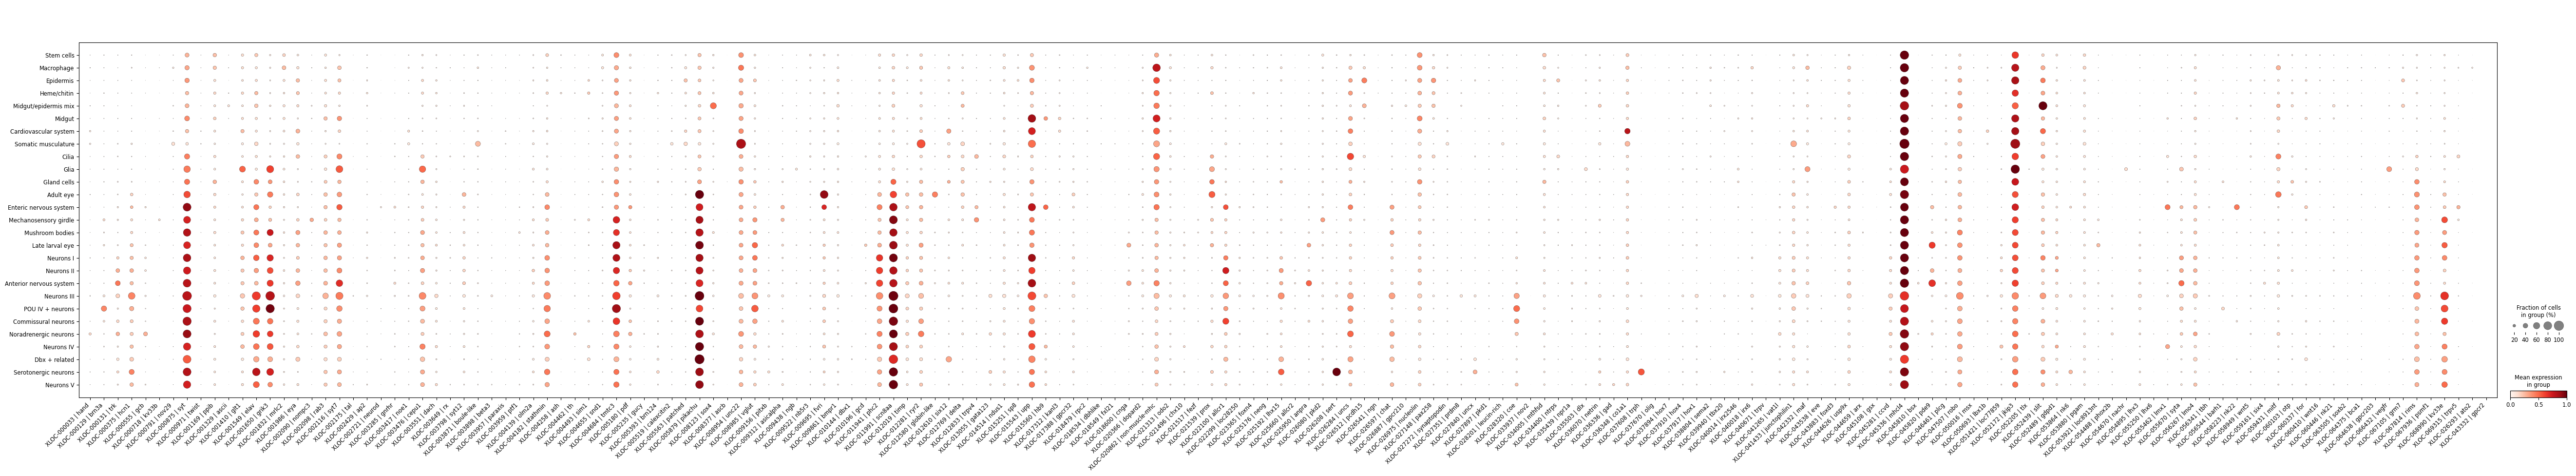

In [12]:
platybrowser_dotplot = sc.pl.dotplot(
    subset_adata, 
    subset_adata.var_names.to_list(),
    groupby=["group_full"],
    return_fig=True,
    **extra_args
)

# Prettier plots
platybrowser_dotplot.make_figure()
ax = platybrowser_dotplot.get_axes()['mainplot_ax']
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
plt.show()

We can access info from the dotplot.

In [13]:
platybrowser_dotplot = sc.pl.dotplot(
    subset_adata, 
    subset_adata.var_names.to_list(),
    groupby=["group_full", "curated_high_res_annotations"], 
    return_fig=True,
    **extra_args
)

Following https://github.com/scverse/scanpy/blob/1.11.3/src/scanpy/plotting/_dotplot.py#L822-L1031 I can extract the dotplot information

In [14]:
obs_bool = platybrowser_dotplot.obs_tidy > extra_args["expression_cutoff"]

# dot_size -> fraction of cells, never changes
dot_size_df = (
    obs_bool.groupby(level=0, observed=True).sum()
        / obs_bool.groupby(level=0, observed=True).count()
)

# dot_color -> strength of expression but with scaled values, scaling can change!
if extra_args["mean_only_expressed"]:
    dot_color_df = (
        platybrowser_dotplot.obs_tidy.mask(~obs_bool)
            .groupby(level=0, observed=True)
            .mean()
            .fillna(0)
        )
else:
    dot_color_df = platybrowser_dotplot.obs_tidy.groupby(level=0, observed=True).mean()

# dot_color depends on the chosen scale
standard_scale = extra_args["standard_scale"]
if standard_scale == "group":
    dot_color_df = dot_color_df.sub(dot_color_df.min(1), axis=0)
    dot_color_df = dot_color_df.div(dot_color_df.max(1), axis=0).fillna(0)
elif standard_scale == "var":
    dot_color_df -= dot_color_df.min(0)
    dot_color_df = (dot_color_df / dot_color_df.max(0)).fillna(0)
elif standard_scale is None:
    pass
else:
    print("Unknown type for standard_scale, ignored")

Here is what you end up with:

In [15]:
dot_color_df.head()   # mean of SCALED expression value

,XLOC-000033 | hand,XLOC-000129 | brn3a,XLOC-000131 | trk,XLOC-000375 | hcn1,XLOC-000555 | gcb,XLOC-000718 | kv33b,XLOC-000791 | nov29,XLOC-000875 | syt,XLOC-000971 | twist,XLOC-001169 | ppib,...,XLOC-064375 | bca1,XLOC-064638 | gpcr203,XLOC-066432 | vegfr,XLOC-067105 | grm7,XLOC-067814 | rims,XLOC-067936 | psmf1,XLOC-068990 | kv33e,XLOC-069315 | trpv5,XLOC-026293 | ato2,XLOC-043332 | gpcr2
group_full_curated_high_res_annotations,,,,,,,,,,,,,,,,,,,,,
Stem cells_clade5sub7,0.008575,0.023465,0.006809,0.029203,0.000000,0.000000,0.027298,0.295012,0.009783,0.135796,...,0.015235,0.0,0.007520,0.015784,0.040474,0.011261,0.096471,0.004923,0.000000,0.0
Stem cells_clade13sub9,0.011383,0.000000,0.048231,0.033948,0.000000,0.009854,0.000000,0.359410,0.000000,0.347147,...,0.013515,0.0,0.000000,0.072119,0.398993,0.046342,0.103999,0.000000,0.000000,0.0
Stem cells_clade5sub16,0.000000,0.024325,0.036512,0.042676,0.011482,0.000000,0.031302,0.497570,0.010434,0.851754,...,0.000000,0.0,0.000000,0.031613,0.417168,0.030213,0.156070,0.022083,0.000000,0.0
Stem cells_clade5sub9,0.007878,0.040882,0.012232,0.021952,0.000000,0.008095,0.023338,0.417698,0.003491,0.664948,...,0.012245,0.0,0.022251,0.004274,0.073129,0.002705,0.058184,0.008643,0.000000,0.0
Stem cells_nocladesub1,0.015570,0.030097,0.023688,0.019427,0.005033,0.003648,0.018589,0.212889,0.010367,0.189863,...,0.018812,0.0,0.010680,0.043584,0.064080,0.020586,0.066591,0.008782,0.001313,0.0


In [16]:
dot_size_df.head()  # Fraction of cells expressing

,XLOC-000033 | hand,XLOC-000129 | brn3a,XLOC-000131 | trk,XLOC-000375 | hcn1,XLOC-000555 | gcb,XLOC-000718 | kv33b,XLOC-000791 | nov29,XLOC-000875 | syt,XLOC-000971 | twist,XLOC-001169 | ppib,...,XLOC-064375 | bca1,XLOC-064638 | gpcr203,XLOC-066432 | vegfr,XLOC-067105 | grm7,XLOC-067814 | rims,XLOC-067936 | psmf1,XLOC-068990 | kv33e,XLOC-069315 | trpv5,XLOC-026293 | ato2,XLOC-043332 | gpcr2
group_full_curated_high_res_annotations,,,,,,,,,,,,,,,,,,,,,
Stem cells_clade5sub7,0.010676,0.021352,0.010676,0.032028,0.000000,0.000000,0.032028,0.295374,0.010676,0.156584,...,0.017794,0.0,0.007117,0.017794,0.049822,0.017794,0.099644,0.007117,0.000000,0.0
Stem cells_clade13sub9,0.016129,0.000000,0.048387,0.048387,0.000000,0.016129,0.000000,0.419355,0.000000,0.403226,...,0.016129,0.0,0.000000,0.096774,0.467742,0.048387,0.129032,0.000000,0.000000,0.0
Stem cells_clade5sub16,0.000000,0.043478,0.043478,0.065217,0.021739,0.000000,0.043478,0.543478,0.021739,0.739130,...,0.000000,0.0,0.000000,0.043478,0.478261,0.043478,0.173913,0.043478,0.000000,0.0
Stem cells_clade5sub9,0.011236,0.050562,0.022472,0.033708,0.000000,0.011236,0.028090,0.438202,0.005618,0.640449,...,0.016854,0.0,0.022472,0.011236,0.101124,0.005618,0.073034,0.011236,0.000000,0.0
Stem cells_nocladesub1,0.018945,0.035183,0.031123,0.023004,0.006766,0.004060,0.023004,0.246279,0.012179,0.225981,...,0.027064,0.0,0.013532,0.062246,0.078484,0.029770,0.082544,0.010825,0.001353,0.0


In [17]:
average_absolute_exp = pd.DataFrame(
    platybrowser_aggregated.layers['sum'],
    index=platybrowser_aggregated.obs_names,
    columns=platybrowser_aggregated.var_names
)

average_absolute_exp.head()

NameError: name 'platybrowser_aggregated' is not defined

We load Platybrowser

In [ ]:
em_unsorted_cols = pd.read_table("./prepped_data/platybrowser_counts.tsv", index_col="label_id")
# forgot to do this, I want alphabetical
em = em_unsorted_cols .sort_index(axis=1)
em.head()

,XLOC-000033 | hand,XLOC-000129 | brn3a,XLOC-000131 | trk,XLOC-000375 | hcn1,XLOC-000555 | gcb,XLOC-000718 | kv33b,XLOC-000791 | nov29,XLOC-000875 | syt,XLOC-000971 | twist,XLOC-001169 | ppib,...,XLOC-060446 | nk21,XLOC-063505 | soxb2,XLOC-064375 | bca1,XLOC-064638 | gpcr203,XLOC-066432 | vegfr,XLOC-067105 | grm7,XLOC-067814 | rims,XLOC-067936 | psmf1,XLOC-068990 | kv33e,XLOC-069315 | trpv5
label_id,,,,,,,,,,,,,,,,,,,,,
1.0,0.00146,0.001112,0.000066,0.002051,0.00648,0.001305,0.000604,0.037809,0.002245,0.0,...,0.009226,0.00068,0.000043,0.012019,0.01309,0.480433,0.009885,0.000325,0.003868,0.023110
2.0,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.0,...,0.000000,0.00000,0.000000,0.000000,0.00000,1.000000,0.000000,0.000000,0.000000,0.000000
3.0,0.00000,0.099017,0.000000,0.003640,0.00000,0.045504,0.000000,0.017474,0.000000,0.0,...,0.002184,0.00000,0.000000,0.000000,0.00000,0.949399,0.000000,0.046596,0.001092,0.002184
4.0,0.00000,0.011179,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.0,...,0.282520,0.00000,0.000000,0.000000,0.00000,0.994919,0.000000,0.000000,0.000000,0.000000
5.0,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.0,...,0.000000,0.00000,0.000000,0.000000,0.00000,0.111111,0.000000,0.000000,0.000000,0.000000


In [ ]:
em.describe()

,XLOC-000033 | hand,XLOC-000129 | brn3a,XLOC-000131 | trk,XLOC-000555 | gcb,XLOC-000718 | kv33b,XLOC-000791 | nov29,XLOC-000971 | twist,XLOC-001169 | ppib,XLOC-001329 | asci,XLOC-001329 | ascii,...,XLOC-059161 | six4,XLOC-060103 | otp,XLOC-060337 | for,XLOC-060410 | wnt16,XLOC-060446 | nk21,XLOC-063505 | soxb2,XLOC-064375 | bca1,XLOC-067105 | grm7,XLOC-067936 | psmf1,XLOC-069315 | trpv5
count,32699.000000,32699.00000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,...,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000
mean,0.033868,0.03728,0.016099,0.022723,0.105217,0.014800,0.043425,0.013717,0.026289,0.009737,...,0.015466,0.014762,0.048479,0.022851,0.015432,0.012909,0.012441,0.141337,0.030821,0.022701
std,0.158917,0.15533,0.103675,0.119528,0.261934,0.095981,0.169259,0.102245,0.124113,0.078002,...,0.094343,0.093329,0.198451,0.129130,0.104937,0.089945,0.094138,0.306049,0.135418,0.118421
min,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.029478,0.000000,0.000000
max,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## New results, looking at clustering

We read Detlev's ordering.

In [ ]:
group_metadata = pd.read_table("/g/arendt/projects/10_platy_6dpf/data/annotations/subclade_ordering_color_scheme.tsv")
group_metadata["merged_info"] = group_metadata["group_full"] + "_" + group_metadata["sub_membership"] 
group_metadata.head()

,group_full,group_slug,group_color,sub_membership,notes,merged_info
0,Stem cells,stem_cells,#FF6EC7,clade5sub7,NaN,Stem cells_clade5sub7
1,Stem cells,stem_cells,#FF6EC7,clade13sub9,NaN,Stem cells_clade13sub9
2,Stem cells,stem_cells,#FF6EC7,clade5sub16,NaN,Stem cells_clade5sub16
3,Stem cells,stem_cells,#FF6EC7,clade5sub9,NaN,Stem cells_clade5sub9
4,Stem cells,stem_cells,#FF6EC7,nocladesub1,NaN,Stem cells_nocladesub1


It looks like it was all converted to a 0-1 scale for me!

In [ ]:
em.describe()['XLOC-043332 | gpcr2']

count    32699.000000
mean         0.003222
std          0.047554
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: XLOC-043332 | gpcr2, dtype: float64

I follow Detlev's ordering.

In [ ]:
average_absolute_exp = average_absolute_exp.reindex(group_metadata["merged_info"].to_list())
average_absolute_exp.head()

,XLOC-000033 | hand,XLOC-000129 | brn3a,XLOC-000131 | trk,XLOC-000375 | hcn1,XLOC-000555 | gcb,XLOC-000718 | kv33b,XLOC-000791 | nov29,XLOC-000875 | syt,XLOC-000971 | twist,XLOC-001169 | ppib,...,XLOC-064375 | bca1,XLOC-064638 | gpcr203,XLOC-066432 | vegfr,XLOC-067105 | grm7,XLOC-067814 | rims,XLOC-067936 | psmf1,XLOC-068990 | kv33e,XLOC-069315 | trpv5,XLOC-026293 | ato2,XLOC-043332 | gpcr2
Stem cells_clade5sub7,3.0,8.0,4.0,9.0,0.0,0.0,11.0,129.0,3.0,61.0,...,5.0,0.0,2.0,5.0,16.0,5.0,31.0,2.0,0.0,0.0
Stem cells_clade13sub9,1.0,0.0,4.0,4.0,0.0,1.0,0.0,41.0,0.0,41.0,...,1.0,0.0,0.0,7.0,46.0,5.0,10.0,0.0,0.0,0.0
Stem cells_clade5sub16,0.0,2.0,2.0,3.0,1.0,0.0,2.0,45.0,1.0,112.0,...,0.0,0.0,0.0,2.0,41.0,2.0,18.0,2.0,0.0,0.0
Stem cells_clade5sub9,2.0,9.0,4.0,7.0,0.0,2.0,6.0,190.0,1.0,367.0,...,3.0,0.0,4.0,2.0,25.0,1.0,33.0,2.0,0.0,0.0
Stem cells_nocladesub1,21.0,35.0,29.0,18.0,5.0,3.0,19.0,256.0,11.0,259.0,...,23.0,0.0,12.0,54.0,62.0,23.0,65.0,12.0,1.0,0.0


We rescale single cell counts

In [ ]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
average_absolute_exp[:] = scaler.fit_transform(average_absolute_exp)
average_absolute_exp.describe()

,XLOC-000033 | hand,XLOC-000129 | brn3a,XLOC-000131 | trk,XLOC-000375 | hcn1,XLOC-000555 | gcb,XLOC-000718 | kv33b,XLOC-000791 | nov29,XLOC-000875 | syt,XLOC-000971 | twist,XLOC-001169 | ppib,...,XLOC-064375 | bca1,XLOC-064638 | gpcr203,XLOC-066432 | vegfr,XLOC-067105 | grm7,XLOC-067814 | rims,XLOC-067936 | psmf1,XLOC-068990 | kv33e,XLOC-069315 | trpv5,XLOC-026293 | ato2,XLOC-043332 | gpcr2
count,267.000000,267.000000,267.000000,267.000000,267.000000,267.000000,267.000000,267.000000,267.000000,267.000000,...,267.000000,267.000000,267.000000,267.000000,267.000000,267.000000,267.000000,267.000000,267.000000,267.0
mean,0.024300,0.037253,0.028928,0.018208,0.034457,0.018924,0.032738,0.027661,0.047255,0.067824,...,0.091091,0.025983,0.010112,0.039697,0.028194,0.077211,0.017059,0.021693,0.014981,0.0
std,0.103677,0.097647,0.076117,0.066254,0.108645,0.102432,0.099196,0.065563,0.116273,0.111877,...,0.139461,0.076533,0.064132,0.119607,0.067892,0.134894,0.065669,0.091102,0.076737,0.0
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
25%,0.000000,0.004444,0.002857,0.001754,0.000000,0.000000,0.000000,0.007975,0.000000,0.013624,...,0.000000,0.000000,0.000000,0.000000,0.006446,0.000000,0.002304,0.000000,0.000000,0.0
50%,0.004739,0.008889,0.009524,0.005263,0.008696,0.000000,0.003984,0.014420,0.021277,0.029973,...,0.035714,0.000000,0.000000,0.004717,0.014504,0.038462,0.004864,0.004950,0.000000,0.0
75%,0.009479,0.026667,0.025714,0.014035,0.017391,0.008772,0.015936,0.029714,0.042553,0.068120,...,0.107143,0.000000,0.004444,0.018868,0.029009,0.076923,0.012929,0.009901,0.000000,0.0
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.0


Some columns have low or zero variance?

In [ ]:
column_variances = average_absolute_exp.var(numeric_only=True)
column_variances.sort_values()[1:20]

XLOC-036336 | gad            0.003838
XLOC-036348 | co1a1          0.003849
XLOC-003898 | beta3          0.003926
XLOC-054488 | phox2b         0.003938
XLOC-037894 | hox7           0.003998
XLOC-012580 | globin-like    0.004003
XLOC-066432 | vegfr          0.004113
XLOC-045281 | ccvd           0.004185
XLOC-028320 | coe            0.004237
XLOC-011991 | scn8aa         0.004259
XLOC-037917 | hox1           0.004279
XLOC-000875 | syt            0.004298
XLOC-068990 | kv33e          0.004312
XLOC-000375 | hcn1           0.004390
XLOC-001410 | glt1           0.004452
XLOC-041265 | vat1l          0.004458
XLOC-009156 | pitxb          0.004463
XLOC-005879 | pikachu        0.004486
XLOC-001549 | elav           0.004501
dtype: float64

In [ ]:
column_variances_em = em.var(numeric_only=True)
column_variances_em.sort_values()[1:40]

XLOC-012580 | globin-like    0.000574
XLOC-035439 | npr1a          0.000613
XLOC-059431 | mitf           0.000998
XLOC-017388 | gpcr32         0.001019
XLOC-027351 | prdm8          0.001073
XLOC-058223 | nk22           0.001209
XLOC-045810 | bsx            0.001214
XLOC-044659 | arx            0.001344
XLOC-012769 | delta          0.001516
XLOC-025660 | allcr2         0.001749
XLOC-003898 | beta3          0.001834
XLOC-005180 | pdf            0.001885
XLOC-026284 | uncs           0.001967
XLOC-052205 | tlx            0.001984
XLOC-043332 | gpcr2          0.002261
XLOC-064638 | gpcr203        0.002393
XLOC-008123 | sox4           0.002406
XLOC-005235 | gucy           0.002514
XLOC-026293 | ato2           0.002583
XLOC-055670 | syta           0.002598
XLOC-008377 | ascb           0.002629
XLOC-040014 | irx2546        0.002774
XLOC-009438 | ngb            0.002813
XLOC-018534 | dbhlike        0.002819
XLOC-056341 | tbh            0.002877
XLOC-052489 | gdpd1          0.003402
XLOC-067814 

In [ ]:
zero_var_cols = average_absolute_exp.columns[average_absolute_exp.var() <= 0.005]
print("Found zero-variance columns for the single cell:", sorted(list(zero_var_cols)))
zero_var_cols_em = em.columns[em.var() <= 0.005]
print("Found zero-variance columns for the EM:", sorted(list(zero_var_cols_em)))
print(f"My overlap is {len([x for x in zero_var_cols_em if x in zero_var_cols])} IDs that I want to remove")
print(f"My total is {len(zero_var_cols) + len(zero_var_cols_em) - len([x for x in zero_var_cols_em if x in zero_var_cols])} IDs that I want to remove")
average_absolute_exp = average_absolute_exp.drop(columns= list(set(zero_var_cols.to_list() + zero_var_cols_em.to_list())))
em = em.drop(columns= list(set(zero_var_cols.to_list() + zero_var_cols_em.to_list())))

Found zero-variance columns for the single cell: ['XLOC-000375 | hcn1', 'XLOC-000875 | syt', 'XLOC-001410 | glt1', 'XLOC-001549 | elav', 'XLOC-001650 | grik3', 'XLOC-003285 | gnrhr', 'XLOC-003898 | beta3', 'XLOC-005879 | pikachu', 'XLOC-009156 | pitxb', 'XLOC-011941 | phc2', 'XLOC-011991 | scn8aa', 'XLOC-012580 | globin-like', 'XLOC-025192 | lhx15', 'XLOC-026208 | sert', 'XLOC-026597 | chat', 'XLOC-027351 | prdm8', 'XLOC-027897 | pkd1', 'XLOC-028320 | coe', 'XLOC-036336 | gad', 'XLOC-036348 | co1a1', 'XLOC-037608 | trph', 'XLOC-037894 | hox7', 'XLOC-037917 | hox1', 'XLOC-041265 | vat1l', 'XLOC-043332 | gpcr2', 'XLOC-045281 | ccvd', 'XLOC-045810 | bsx', 'XLOC-053864 | nk6', 'XLOC-054488 | phox2b', 'XLOC-055250 | lhx6', 'XLOC-066432 | vegfr', 'XLOC-067814 | rims', 'XLOC-068990 | kv33e']
Found zero-variance columns for the EM: ['XLOC-003285 | gnrhr', 'XLOC-003898 | beta3', 'XLOC-003957 | paraxis', 'XLOC-003959 | ptf1', 'XLOC-004258 | ash', 'XLOC-005180 | pdf', 'XLOC-005235 | gucy', 'XLOC-

<Figure size 2400x1600 with 0 Axes>

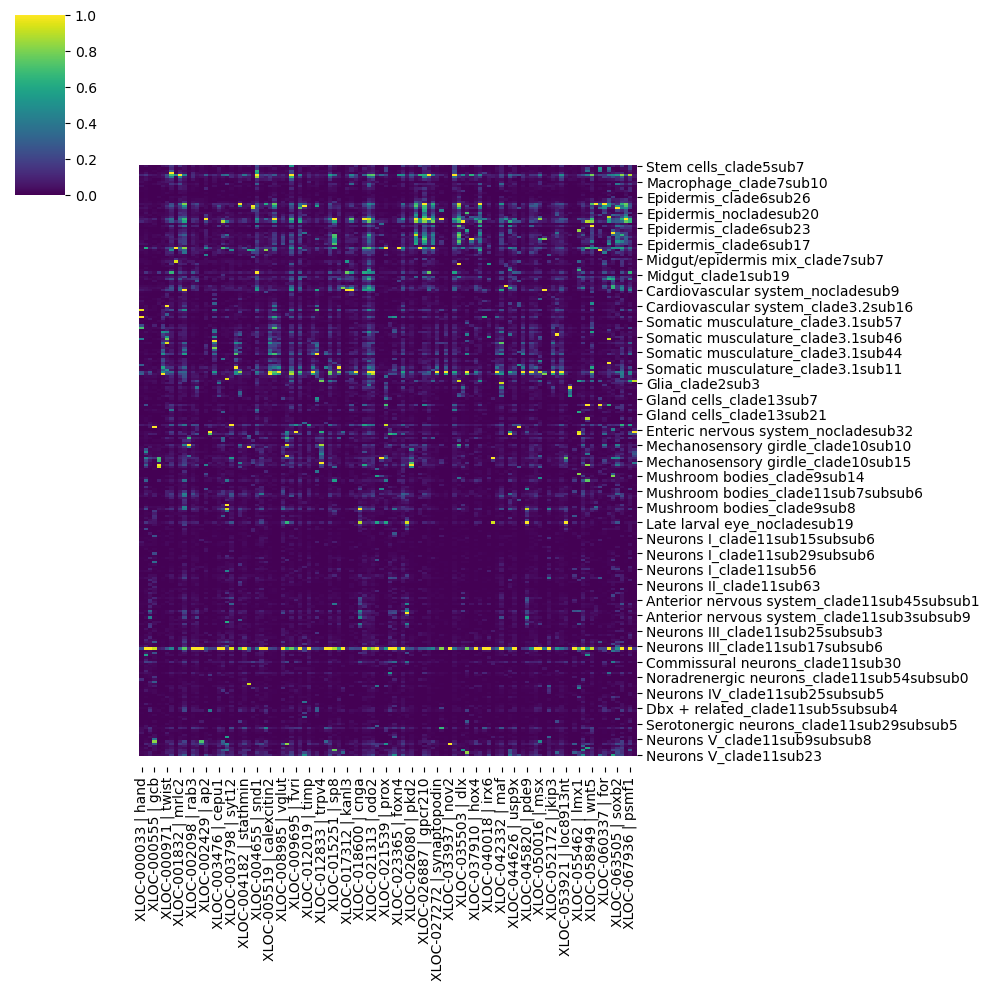

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(24, 16))

sns.clustermap(average_absolute_exp,
               col_cluster=False,
               row_cluster=False,
               cmap='viridis',
               annot=False,
               fmt='.2f')

plt.show()